# Passau MedCo · Attrition Prediction and XAI

Compare supervised classifiers for employee attrition. Select the model on the training partition, then compare predictions on the historical test split.

## 1. Imports

Import the tools for preprocessing, training, evaluation, and plotting.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from joblib import parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

## 2. Load data

Read the employee CSV used for model training.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip()

## 3. Model training and predictions

Compare two logistic regressions and a random forest. Use average precision (AP) to measure how well each model ranks employees who left above those who stayed. Only 190 of the 1,176 training employees left, so the evaluation also shows precision, recall, and the actual error counts.

### Prepare features and split the data

Keep the original stratified 80/20 split to make the results comparable with earlier runs. Determine constant features from the training data. The test split has been used in earlier notebook versions and serves as a historical comparison.

In [3]:
random_seed = 42
assert not employees.duplicated().any(), "Review duplicate employee rows."
assert employees["EmployeeNumber"].notna().all() and employees["EmployeeNumber"].is_unique
assert set(employees["Attrition"]) == {"Yes", "No"}, "Review the Attrition labels."

X = employees.drop(columns=["EmployeeNumber", "Attrition"])
y = employees["Attrition"].eq("Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=random_seed
)
constant_columns = X_train.columns[X_train.nunique(dropna=False).eq(1)]
X_train = X_train.drop(columns=constant_columns)
X_test = X_test.drop(columns=constant_columns)

display(pd.DataFrame({
    "Employees": [len(y_train), len(y_test)],
    "Employees who left": [y_train.sum(), y_test.sum()],
}, index=["Train", "Test"]))

,Employees,Employees who left
Train,1176,190
Test,294,47


### Compare feature encodings and set up the search

The EDA found that attrition varies unevenly across job levels and stock option levels. Treating the codes as numbers gives logistic regression a single linear slope per feature. One-hot encoding allows a separate coefficient for each level. Both logistic variants use the same search grid, so their comparison isolates the encoding change. The random forest provides a nonlinear comparison.

In [4]:
categorical_features = X_train.select_dtypes(include="str").columns.tolist()
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
skewed_features = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
eda_levels = ["JobLevel", "StockOptionLevel"]

reference_name = "Logistic regression · numeric levels"
eda_model_name = "Logistic regression · categorical levels"

inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=random_seed)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=19)
search_options = {"cv": inner_cv, "scoring": "average_precision", "n_jobs": 4, "error_score": "raise"}
logistic_grid = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0],
    "logisticregression__class_weight": [None, "balanced"],
    "columntransformer__skewed": [StandardScaler(), PowerTransformer()],
}

def make_logistic_search(level_features=()):
    numeric_columns = [
        column for column in numeric_features
        if column not in skewed_features and column not in level_features
    ]
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_columns),
        ("skewed", StandardScaler(), skewed_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), [*categorical_features, *level_features]),
    ])
    model = make_pipeline(preprocessing, LogisticRegression(max_iter=1000))
    return GridSearchCV(model, logistic_grid, **search_options)

forest_preprocessing = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
forest = make_pipeline(
    forest_preprocessing,
    RandomForestClassifier(n_estimators=150, random_state=random_seed),
)
searches = {
    reference_name: make_logistic_search(),
    eda_model_name: make_logistic_search(eda_levels),
    "Random forest": GridSearchCV(
        forest,
        {
            "randomforestclassifier__max_depth": [8, None],
            "randomforestclassifier__min_samples_leaf": [1, 3, 8],
            "randomforestclassifier__max_features": ["sqrt", 0.6],
            "randomforestclassifier__class_weight": [None, "balanced"],
        },
        **search_options,
    ),
}

### Select the model with nested cross-validation

Use the same five outer training folds for all three candidates. Within each fold, select hyperparameters using four inner folds, then score the outer validation rows. Store those predictions for threshold selection. The test scores play no role in choosing the model or thresholds.

In [5]:
out_of_fold_scores = pd.DataFrame(index=X_train.index, columns=searches.keys(), dtype=float)
fold_results = []

with parallel_config(backend="loky", inner_max_num_threads=1):
    for fold, (fit_indices, validation_indices) in enumerate(outer_cv.split(X_train, y_train), start=1):
        X_fit, X_validation = X_train.iloc[fit_indices], X_train.iloc[validation_indices]
        y_fit, y_validation = y_train.iloc[fit_indices], y_train.iloc[validation_indices]

        for model_name, search in searches.items():
            fitted_search = clone(search).fit(X_fit, y_fit)
            validation_scores = fitted_search.predict_proba(X_validation)[:, 1]
            out_of_fold_scores.loc[X_validation.index, model_name] = validation_scores
            fold_results.append({
                "Fold": fold,
                "Model": model_name,
                "AP": average_precision_score(y_validation, validation_scores),
            })

fold_ap = pd.DataFrame(fold_results).pivot(index="Fold", columns="Model", values="AP")
paired_differences = fold_ap.sub(fold_ap[reference_name], axis="index")
cv_results = pd.DataFrame({
    "Mean AP": fold_ap.mean(),
    "Fold SD": fold_ap.std(),
    "Mean AP change vs numeric levels": paired_differences.mean(),
}).sort_values("Mean AP", ascending=False)
display(cv_results.round(3))
selected_name = cv_results.index[0]
print(f"Selected model: {selected_name}")

,Mean AP,Fold SD,Mean AP change vs numeric levels
Model,,,
Logistic regression · categorical levels,0.691,0.063,0.022
Logistic regression · numeric levels,0.669,0.081,0.000
Random forest,0.542,0.088,-0.127


Selected model: Logistic regression · categorical levels


### Set thresholds and refit on the training partition

F1 balances precision and recall. F2 puts more weight on recall. For a stricter comparison, also use the highest threshold that still achieves at least 50% recall on the pooled outer-fold predictions. Choose all thresholds from the outer-fold predictions, where each employee was scored by a model tuned and fitted without that employee. Then run each model's search on the full training partition.

In [6]:
def choose_thresholds(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    precision, recall = precision[:-1], recall[:-1]
    choices = {}
    for beta in (1, 2):
        beta_squared = beta ** 2
        denominator = (beta_squared * precision + recall).clip(min=1e-12)
        f_beta = (1 + beta_squared) * precision * recall / denominator
        choices[f"F{beta}"] = float(thresholds[f_beta.argmax()])
    recall_target = 0.50
    choices[f"{recall_target:.0%} CV recall"] = float(thresholds[recall >= recall_target][-1])
    return choices

model_thresholds = {
    model_name: choose_thresholds(y_train, out_of_fold_scores[model_name])
    for model_name in searches
}
with parallel_config(backend="loky", inner_max_num_threads=1):
    fitted_searches = {name: clone(search).fit(X_train, y_train) for name, search in searches.items()}

selected_model = fitted_searches[selected_name].best_estimator_
decision_threshold = model_thresholds[selected_name]["F1"]
print("Selected hyperparameters:")
for parameter, value in fitted_searches[selected_name].best_params_.items():
    print(f"  {parameter}: {value}")

display(pd.DataFrame(model_thresholds).T.round(3))

Selected hyperparameters:
  columntransformer__skewed: PowerTransformer()
  logisticregression__C: 1.0
  logisticregression__class_weight: None


,F1,F2,50% CV recall
Logistic regression · numeric levels,0.338,0.198,0.427
Logistic regression · categorical levels,0.343,0.279,0.466
Random forest,0.390,0.122,0.353


### Compare results on the historical test split

Compare the fitted models with the always-stayed baseline. AP summarizes the entire ranking, while precision, recall, and the error counts describe predictions at the chosen threshold.

In [7]:
def summarize_predictions(labels, scores, predictions):
    return {
        "AP": average_precision_score(labels, scores),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions, zero_division=0),
        "F1": f1_score(labels, predictions, zero_division=0),
        "F2": fbeta_score(labels, predictions, beta=2, zero_division=0),
        "Employees who left detected": int((predictions & labels.eq(1)).sum()),
        "False alarms": int((predictions & labels.eq(0)).sum()),
    }

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_scores = baseline.predict_proba(X_test)[:, 1]
test_results = {
    ("Majority baseline", "Always stayed"): summarize_predictions(
        y_test, baseline_scores, baseline.predict(X_test).astype(bool)
    )
}
for model_name in cv_results.index:
    model_scores = fitted_searches[model_name].predict_proba(X_test)[:, 1]
    for threshold_name, threshold in model_thresholds[model_name].items():
        test_results[(model_name, threshold_name)] = summarize_predictions(
            y_test, model_scores, model_scores >= threshold
        )

test_metrics = pd.DataFrame.from_dict(test_results, orient="index")
test_metrics.index.names = ["Model", "Threshold"]
display(test_metrics.round(3))

test_scores = selected_model.predict_proba(X_test)[:, 1]
test_predictions = test_scores >= decision_threshold

AP  Precision  \
Model                                    Threshold                         
Majority baseline                        Always stayed  0.160      0.000   
Logistic regression · categorical levels F1             0.647      0.571   
                                         F2             0.647      0.517   
                                         50% CV recall  0.647      0.719   
Logistic regression · numeric levels     F1             0.616      0.585   
                                         F2             0.616      0.419   
                                         50% CV recall  0.616      0.778   
Random forest                            F1             0.459      0.500   
                                         F2             0.459      0.279   
                                         50% CV recall  0.459      0.500   

                                                        Recall     F1     F2  \
Model                                    Threshold                             
Majority baseline                        Always stayed   0.000  0.000  0.000   
Logistic regression · categorical levels F1              0.511  0.539  0.522   
                                         F2              0.660  0.579  0.625   
                                         50% CV recall   0.489  0.582  0.523   
Logistic regression · numeric levels     F1              0.511  0.545  0.524   
                                         F2              0.660  0.512  0.592   
                                         50% CV recall   0.447  0.568  0.488   
Random forest                            F1              0.234  0.319  0.262   
                                         F2              0.830  0.417  0.595   
                                         50% CV recall   0.277  0.356  0.304   

                                                        Employees who left detected  \
Model                                    Threshold                                    
Majority baseline                        Always stayed                            0   
Logistic regression · categorical levels F1                                      24   
                                         F2                                      31   
                                         50% CV recall                           23   
Logistic regression · numeric levels     F1                                      24   
                                         F2                                      31   
                                         50% CV recall                           21   
Random forest                            F1                                      11   
                                         F2                                      39   
                                         50% CV recall                           13   

                                                        False alarms  
Model                                    Threshold                    
Majority baseline                        Always stayed             0  
Logistic regression · categorical levels F1                       18  
                                         F2                       29  
                                         50% CV recall             9  
Logistic regression · numeric levels     F1                       17  
                                         F2                       43  
                                         50% CV recall             6  
Random forest                            F1                       11  
                                         F2                      101  
                                         50% CV recall            13

### Compare prediction errors

Compare the selected model at the balanced F1 threshold, the recall-focused F2 threshold, and the stricter threshold set at 50% cross-validated recall.

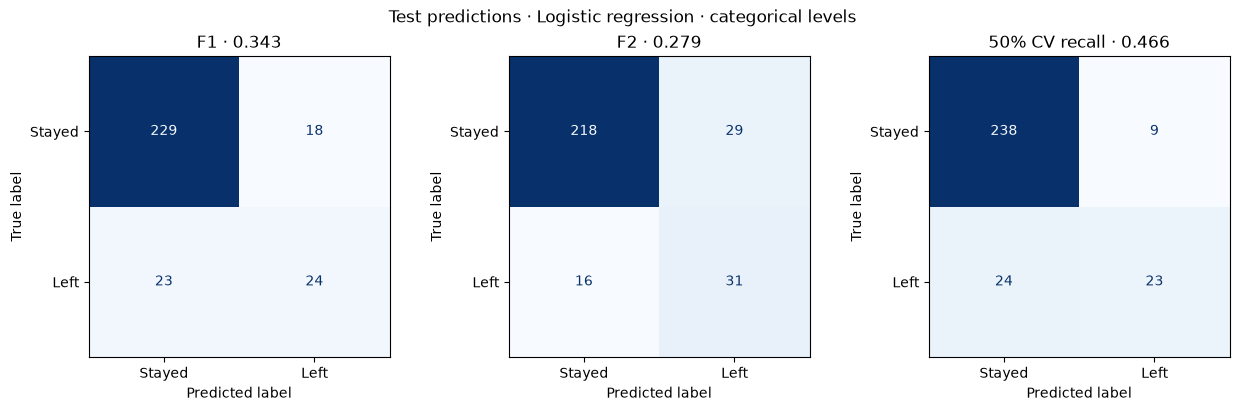

In [8]:
%matplotlib inline

selected_thresholds = model_thresholds[selected_name]
fig, axes = plt.subplots(1, len(selected_thresholds), figsize=(12.6, 4), layout="constrained")
for ax, (threshold_name, threshold) in zip(axes, selected_thresholds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_scores >= threshold, labels=[0, 1], display_labels=["Stayed", "Left"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{threshold_name} · {threshold:.3f}")
fig.suptitle(f"Test predictions · {selected_name}")
plt.show()

### Model takeaway

- **Model selection:** Logistic regression with categorical job and stock option levels achieved the highest mean outer-fold AP (0.691), ahead of numeric levels (0.669) and random forest (0.542). The selected fit uses `C=1.0` and a power transform for the three skewed features.
- **Historical test split:** The categorical model raised AP from 0.616 to 0.647. At F2, both logistic variants found 31 of 47 employees who left. False alarms fell from 43 to 29 with categorical levels. At F1, the categorical model found 24 with 18 false alarms, compared with 24 and 17 for the numeric variant.
- **Precision and recall:** The threshold set at 50% cross-validated recall found 23 of 47 employees who left, with nine false alarms (71.9% precision) on the historical split. F1 found 24, with 18 false alarms (57.1% precision), and remains the default for the next notebook section. Use these threshold results as a comparison on a previously evaluated split.

## 4. Model explanations

Planned next step: explain three predictions with LIME and add a global explanation of the selected model.